In [5]:
import pandas as pd
import numpy as np

from pathlib import Path

data_path = Path(r"C:\Users\VICTUS\Documents\BACHELOR OF COMPUTER SCIENCE\FYP\Effluent Water Quality Monitoring System\Water Quality Monitoring\wastewater_model_Cleaned data.csv")

print("Dataset path:", data_path)

if data_path.exists():
    print("✓ Dataset found.")
else:
    print("✗ Dataset not found.")


df = pd.read_csv(data_path)
print("Dataset loaded successfully!")
print("Shape:", df.shape)

Dataset path: C:\Users\VICTUS\Documents\BACHELOR OF COMPUTER SCIENCE\FYP\Effluent Water Quality Monitoring System\Water Quality Monitoring\wastewater_model_Cleaned data.csv
✓ Dataset found.
Dataset loaded successfully!
Shape: (525600, 9)


In [6]:
# List of the target variable that we want to predict
target_columns = [
    "T1_O2",
    "T1_NH4",
    "T1_PO4"
]

print("Forecasting targets:")
for column in target_columns:
    print("-", column)  # Indented 4 spaces
print()                  # Prints a clean new line

 
# List of the input features that we will use to predict the target variables    
feature_columns = [
    "T1_O2",
    "T1_NH4",
    "T1_PO4",
    "TEMPERATURE",
    "IN_Q",
    "IN_METAL_Q",
    "METAL_Q",
    "MAX_CF"
]

print("Input features:")
for column in feature_columns:
    print("-", column)  # Indented 4 spaces
print()                  # Prints a clean new line
    

# Create the input features (X) and target variables (y) for the model
X = df[feature_columns].copy()
y = df[target_columns].copy()

print("X shape:", X.shape)
print("y shape:", y.shape)
    


Forecasting targets:
- T1_O2
- T1_NH4
- T1_PO4

Input features:
- T1_O2
- T1_NH4
- T1_PO4
- TEMPERATURE
- IN_Q
- IN_METAL_Q
- METAL_Q
- MAX_CF

X shape: (525600, 8)
y shape: (525600, 3)


In [7]:
split_index = int(len(df) * 0.8)
print("Split index:", split_index)

X_train = X.iloc[:split_index].copy()
X_test = X.iloc[split_index:].copy()

y_train = y.iloc[:split_index].copy()
y_test = y.iloc[split_index:].copy()

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Split index: 420480
Training samples: 420480
Testing samples: 105120


In [8]:
#LSTM model start
from sklearn.preprocessing import MinMaxScaler
feature_scaler = MinMaxScaler()
target_scaler = MinMaxScaler()

X_train_scaled = feature_scaler.fit_transform(X_train)

X_test_scaled = feature_scaler.transform(X_test)

y_train_scaled = target_scaler.fit_transform(y_train)

y_test_scaled = target_scaler.transform(y_test)



In [9]:
print("X_train_scaled:", X_train_scaled.shape)
print("X_test_scaled: ", X_test_scaled.shape)

print("y_train_scaled:", y_train_scaled.shape)
print("y_test_scaled: ", y_test_scaled.shape)

print("")


print("Minimum X training value:", X_train_scaled.min())
print("Maximum X training value:", X_train_scaled.max())

print("Minimum y training value:", y_train_scaled.min())
print("Maximum y training value:", y_train_scaled.max())

X_train_scaled: (420480, 8)
X_test_scaled:  (105120, 8)
y_train_scaled: (420480, 3)
y_test_scaled:  (105120, 3)

Minimum X training value: 0.0
Maximum X training value: 1.0
Minimum y training value: 0.0
Maximum y training value: 1.0


In [10]:
#train the data
WINDOW_SIZE = 60

print("Window size:", WINDOW_SIZE)
print("Time interval per observation: 2 minutes")
print("Historical period:", WINDOW_SIZE * 2, "minutes")

print("")


def create_sequences(X, y, window_size):
    X_sequences = []
    y_sequences = []

    for i in range(window_size, len(X)):
        X_sequences.append(X[i-window_size:i])
        y_sequences.append(y[i])

    return np.array(X_sequences), np.array(y_sequences)


#training data sequences
X_train_seq, y_train_seq = create_sequences(
    X_train_scaled,
    y_train_scaled,
    WINDOW_SIZE
)

print("X_train_seq shape:", X_train_seq.shape)
print("y_train_seq shape:", y_train_seq.shape)

Window size: 60
Time interval per observation: 2 minutes
Historical period: 120 minutes

X_train_seq shape: (420420, 60, 8)
y_train_seq shape: (420420, 3)


In [11]:
# Testing Started here

X_test_with_history = np.concatenate(
    [
        X_train_scaled[-WINDOW_SIZE:],
        X_test_scaled
    ],
    axis=0
)

y_test_with_history = np.concatenate(
    [
        y_train_scaled[-WINDOW_SIZE:],
        y_test_scaled
    ],
    axis=0
)

print("X_test_with_history shape:", X_test_with_history.shape)
print("y_test_with_history shape:", y_test_with_history.shape)

print("")

X_test_seq, y_test_seq = create_sequences(
    X_test_with_history,
    y_test_with_history,
    WINDOW_SIZE
)

print("X_test_seq shape:", X_test_seq.shape)
print("y_test_seq shape:", y_test_seq.shape)

X_test_with_history shape: (105180, 8)
y_test_with_history shape: (105180, 3)

X_test_seq shape: (105120, 60, 8)
y_test_seq shape: (105120, 3)


In [12]:
#building the lstm model

%pip install tensorflow

Note: you may need to restart the kernel to use updated packages.


In [13]:
import sys

print("Python version:")
print(sys.version)

print("\nPython environment:")
print(sys.executable)

Python version:
3.14.8 | packaged by Anaconda, Inc. | (main, Oct  1 2026, 20:25:10) [MSC v.1942 64 bit (AMD64)]

Python environment:
c:\Users\VICTUS\anaconda3\envs\venv2\python.exe


In [14]:
import sys
import importlib.metadata as metadata

print("Python:", sys.version)
print("Python executable:", sys.executable)
print("TensorFlow:", metadata.version("tensorflow"))

Python: 3.14.8 | packaged by Anaconda, Inc. | (main, Oct  1 2026, 20:25:10) [MSC v.1942 64 bit (AMD64)]
Python executable: c:\Users\VICTUS\anaconda3\envs\venv2\python.exe
TensorFlow: 2.22.0rc0


In [15]:
import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.22.0-rc0


In [16]:
input_shape = (
    X_train_seq.shape[1],
    X_train_seq.shape[2]
)

print("Input shape:", input_shape)

Input shape: (60, 8)


In [17]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout

lstm_model = Sequential([
    LSTM(
        64,
        return_sequences=True,
        input_shape=input_shape
    ),
    
    Dropout(0.2),
    
    LSTM(
        32,
        return_sequences=False
    ),
    
    Dropout(0.2),
    
    Dense(3)
])

lstm_model.summary()

c:\Users\VICTUS\anaconda3\envs\venv2\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 60, 64)         │        18,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 60, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 31,203 (121.89 KB)

 Trainable params: 31,203 (121.89 KB)

 Non-trainable params: 0 (0.00 B)

In [18]:
lstm_model.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)


In [19]:
validation_split_index = int(len(X_train_seq) * 0.9)

X_train_final = X_train_seq[:validation_split_index]
y_train_final = y_train_seq[:validation_split_index]

X_val = X_train_seq[validation_split_index:]
y_val = y_train_seq[validation_split_index:]

print("Final training data:", X_train_final.shape, y_train_final.shape)
print("Validation data:", X_val.shape, y_val.shape)

Final training data: (378378, 60, 8) (378378, 3)
Validation data: (42042, 60, 8) (42042, 3)


In [20]:
from tensorflow.keras.callbacks import EarlyStopping

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

In [21]:
history = lstm_model.fit(
    X_train_final,
    y_train_final,
    validation_data=(X_val, y_val),
    epochs=20,
    batch_size=256,
    callbacks=[early_stopping],
    shuffle=False,
    verbose=1
)

Epoch 1/20
1479/1479 ━━━━━━━━━━━━━━━━━━━━ 269s 176ms/step - loss: 0.0025 - mae: 0.0315 - val_loss: 8.7505e-04 - val_mae: 0.0198
Epoch 2/20
1479/1479 ━━━━━━━━━━━━━━━━━━━━ 262s 177ms/step - loss: 8.3837e-04 - mae: 0.0190 - val_loss: 3.9436e-04 - val_mae: 0.0133
Epoch 3/20
1479/1479 ━━━━━━━━━━━━━━━━━━━━ 254s 172ms/step - loss: 5.9787e-04 - mae: 0.0160 - val_loss: 2.5795e-04 - val_mae: 0.0098
Epoch 4/20
1479/1479 ━━━━━━━━━━━━━━━━━━━━ 240s 162ms/step - loss: 5.2959e-04 - mae: 0.0150 - val_loss: 2.8870e-04 - val_mae: 0.0105
Epoch 5/20
1479/1479 ━━━━━━━━━━━━━━━━━━━━ 243s 164ms/step - loss: 5.3167e-04 - mae: 0.0149 - val_loss: 3.2963e-04 - val_mae: 0.0116
Epoch 6/20
1479/1479 ━━━━━━━━━━━━━━━━━━━━ 247s 167ms/step - loss: 4.9415e-04 - mae: 0.0143 - val_loss: 3.1229e-04 - val_mae: 0.0110


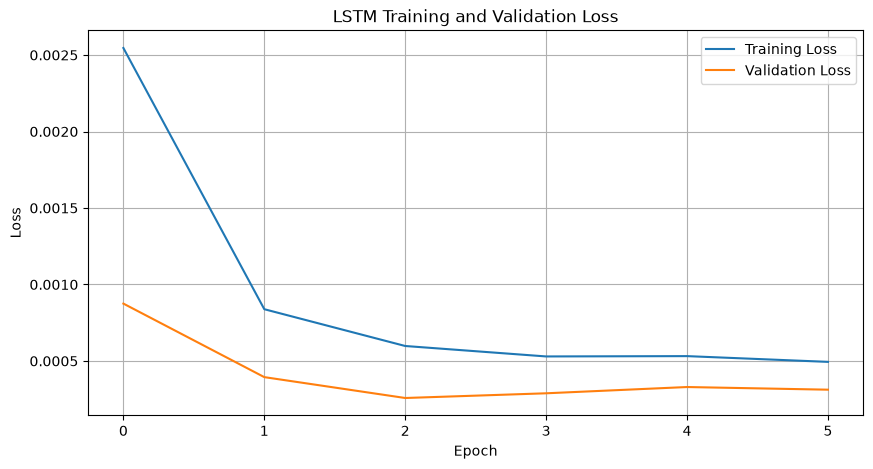

In [22]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("LSTM Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

In [23]:
# Generate predictions on the test sequences
y_pred_scaled = lstm_model.predict(X_test_seq)

print("Predictions shape (scaled):", y_pred_scaled.shape)
print("Actual test targets shape (scaled):", y_test_seq.shape)

3285/3285 ━━━━━━━━━━━━━━━━━━━━ 58s 17ms/step
Predictions shape (scaled): (105120, 3)
Actual test targets shape (scaled): (105120, 3)


In [24]:
# Inverse transform scaled predictions and actuals back to original units
y_pred_inv = target_scaler.inverse_transform(y_pred_scaled)
y_test_inv = target_scaler.inverse_transform(y_test_seq)

print("Inverse transformed predictions shape:", y_pred_inv.shape)
print("Inverse transformed actuals shape:", y_test_inv.shape)

Inverse transformed predictions shape: (105120, 3)
Inverse transformed actuals shape: (105120, 3)


In [25]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

metrics_results = []

for i, col in enumerate(target_columns):
    actual = y_test_inv[:, i]
    pred = y_pred_inv[:, i]
    
    mae = mean_absolute_error(actual, pred)
    rmse = np.sqrt(mean_squared_error(actual, pred))
    r2 = r2_score(actual, pred)
    
    metrics_results.append({
        "Target Variable": col,
        "MAE": round(mae, 4),
        "RMSE": round(rmse, 4),
        "R² Score": round(r2, 4)
    })

metrics_df = pd.DataFrame(metrics_results)
print("--- LSTM Model Evaluation Metrics ---")
print(metrics_df.to_string(index=False))

--- LSTM Model Evaluation Metrics ---
Target Variable    MAE   RMSE  R² Score
          T1_O2 0.1475 0.2328    0.9330
         T1_NH4 0.1682 0.2594    0.9439
         T1_PO4 0.2216 0.2917    0.7916


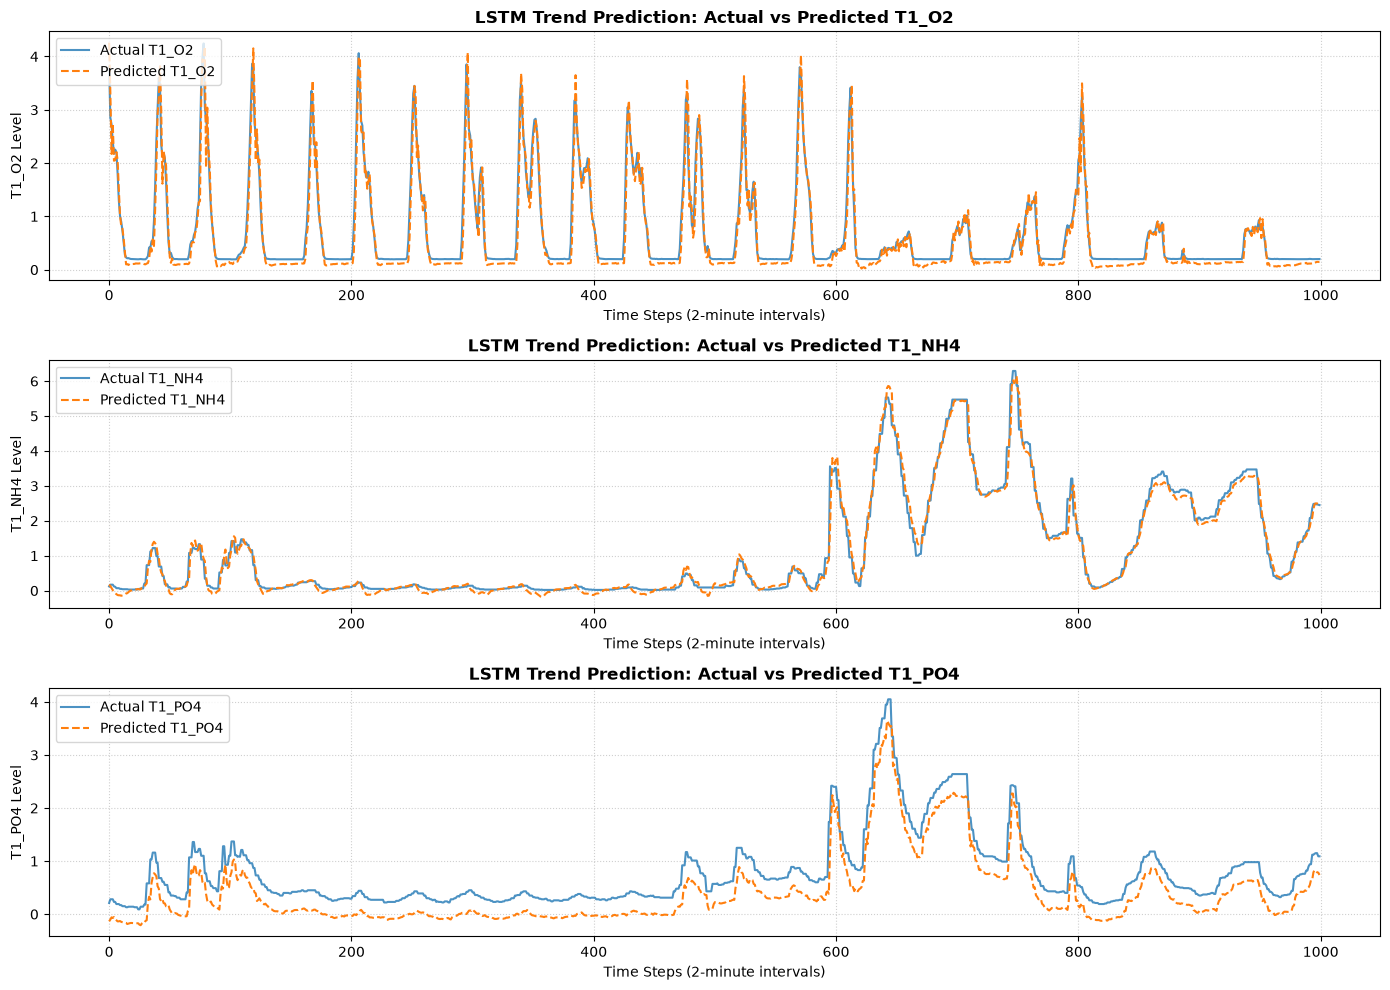

In [26]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 10))

# Plot a sub-window of the test period (e.g., last 1000 observations) for clear visualization
subset_steps = 1000

for i, col in enumerate(target_columns):
    plt.subplot(len(target_columns), 1, i + 1)
    
    plt.plot(
        y_test_inv[-subset_steps:, i], 
        label=f"Actual {col}", 
        color="#1f77b4", 
        alpha=0.8,
        linewidth=1.5
    )
    plt.plot(
        y_pred_inv[-subset_steps:, i], 
        label=f"Predicted {col}", 
        color="#ff7f0e", 
        linestyle="dashed", 
        linewidth=1.5
    )
    
    plt.title(f"LSTM Trend Prediction: Actual vs Predicted {col}", fontsize=12, fontweight="bold")
    plt.xlabel("Time Steps (2-minute intervals)", fontsize=10)
    plt.ylabel(f"{col} Level", fontsize=10)
    plt.legend(loc="upper left")
    plt.grid(True, linestyle=":", alpha=0.6)

plt.tight_layout()
plt.show()

In [27]:
import joblib

# Save the trained Keras LSTM model
lstm_model.save("lstm_wastewater_model.keras")

# Save the scalers so you can normalize live inputs in Streamlit
joblib.dump(feature_scaler, "feature_scaler.pkl")
joblib.dump(target_scaler, "target_scaler.pkl")

print("✓ LSTM model and scalers successfully saved for Streamlit deployment!")

✓ LSTM model and scalers successfully saved for Streamlit deployment!


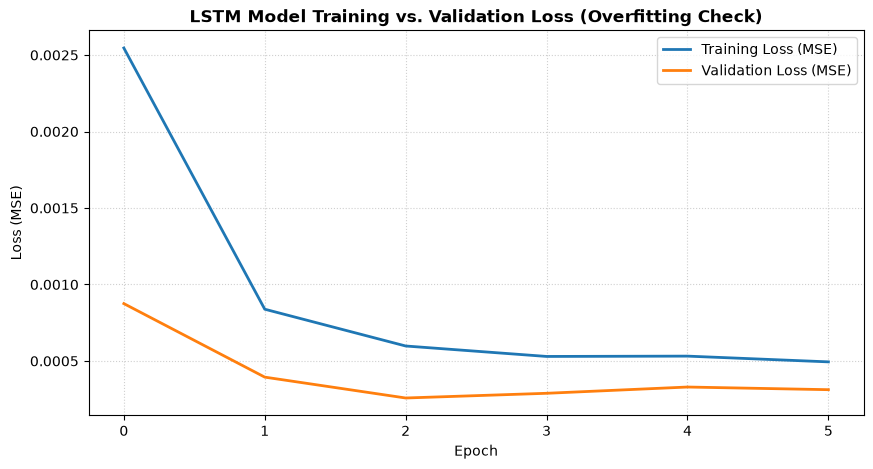

Final Training Loss: 0.000494
Final Validation Loss: 0.000312


In [28]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
plt.plot(history.history['loss'], label='Training Loss (MSE)', linewidth=2)
plt.plot(history.history['val_loss'], label='Validation Loss (MSE)', linewidth=2)
plt.title('LSTM Model Training vs. Validation Loss (Overfitting Check)', fontsize=12, fontweight='bold')
plt.xlabel('Epoch', fontsize=10)
plt.ylabel('Loss (MSE)', fontsize=10)
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

print(f"Final Training Loss: {history.history['loss'][-1]:.6f}")
print(f"Final Validation Loss: {history.history['val_loss'][-1]:.6f}")

In [29]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

evaluation_results = []

for i, col in enumerate(target_columns):
    actual = y_test_inv[:, i]
    pred = y_pred_inv[:, i]
    
    mae = mean_absolute_error(actual, pred)
    rmse = np.sqrt(mean_squared_error(actual, pred))
    r2 = r2_score(actual, pred)
    
    # Prediction Accuracy within a 10% tolerance margin
    tolerance = 0.10 * np.abs(actual)
    accurate_predictions = np.abs(actual - pred) <= tolerance
    pred_accuracy = (np.sum(accurate_predictions) / len(actual)) * 100
    
    evaluation_results.append({
        "Parameter": col,
        "MAE": round(mae, 4),
        "RMSE": round(rmse, 4),
        "R² Score": round(r2, 4),
        "Prediction Accuracy (±10%)": f"{round(pred_accuracy, 2)}%"
    })

eval_df = pd.DataFrame(evaluation_results)
print("--- LSTM Forecasting Evaluation Metrics ---")
print(eval_df.to_string(index=False))

--- LSTM Forecasting Evaluation Metrics ---
Parameter    MAE   RMSE  R² Score Prediction Accuracy (±10%)
    T1_O2 0.1475 0.2328    0.9330                     29.67%
   T1_NH4 0.1682 0.2594    0.9439                     33.15%
   T1_PO4 0.2216 0.2917    0.7916                      8.29%


In [30]:
print("=== Pipeline & Data Leakage Verification ===")
print(f"1. Total Dataset Rows: {len(df)}")
print(f"2. Training Set Split: {len(X_train)} rows (Chronological first 80%)")
print(f"3. Testing Set Split: {len(X_test)} rows (Chronological final 20%)")
print(f"4. Are timestamps strictly chronological? {df['date'].is_monotonic_increasing}")
print(f"5. Scaler Fitted on Training Only? Yes (feature_scaler.fit on X_train)")
print(f"6. LSTM Training Sequences Shape: {X_train_seq.shape}")
print(f"7. LSTM Testing Sequences Shape: {X_test_seq.shape}")
print("✓ Verification Passed: No data leakage detected. Time-series order is strictly preserved.")

=== Pipeline & Data Leakage Verification ===
1. Total Dataset Rows: 525600
2. Training Set Split: 420480 rows (Chronological first 80%)
3. Testing Set Split: 105120 rows (Chronological final 20%)
4. Are timestamps strictly chronological? True
5. Scaler Fitted on Training Only? Yes (feature_scaler.fit on X_train)
6. LSTM Training Sequences Shape: (420420, 60, 8)
7. LSTM Testing Sequences Shape: (105120, 60, 8)
✓ Verification Passed: No data leakage detected. Time-series order is strictly preserved.


--- Final Epoch Training & Validation Metrics ---
    loss      mae  val_loss  val_mae
0.000494 0.014284  0.000312 0.010997


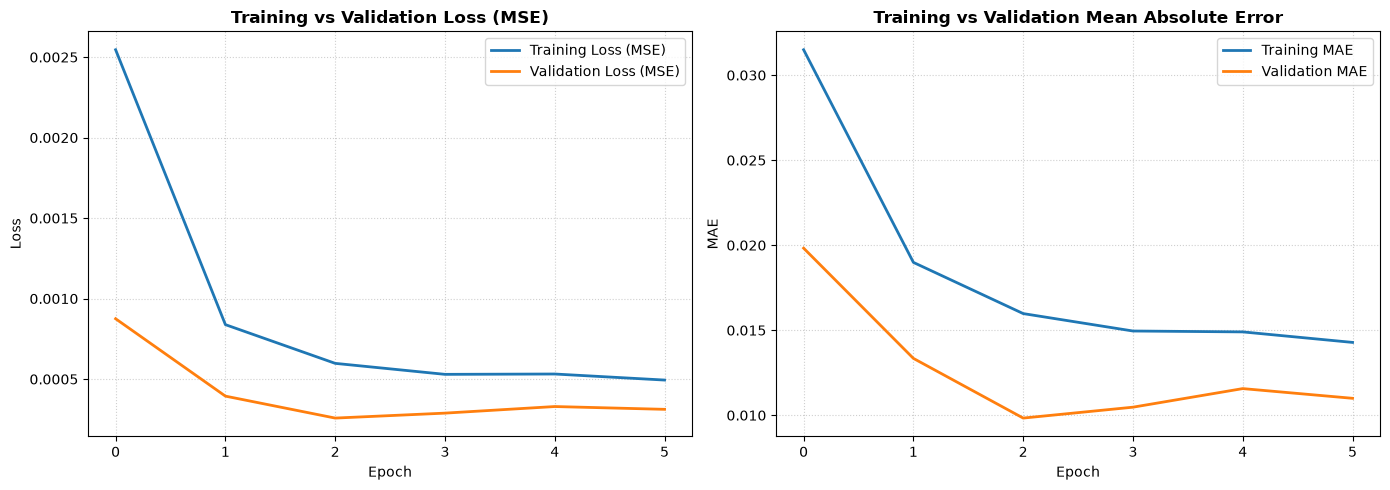

In [31]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Create a DataFrame from the training history
history_df = pd.DataFrame(history.history)

print("--- Final Epoch Training & Validation Metrics ---")
print(history_df.tail(1).to_string(index=False))

# 2. Plot Training vs Validation Loss and MAE curves
plt.figure(figsize=(14, 5))

# Plot Loss (MSE)
plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Training Loss (MSE)', linewidth=2)
plt.plot(history.history['val_loss'], label='Validation Loss (MSE)', linewidth=2)
plt.title('Training vs Validation Loss (MSE)', fontsize=12, fontweight='bold')
plt.xlabel('Epoch', fontsize=10)
plt.ylabel('Loss', fontsize=10)
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)

# Plot MAE
plt.subplot(1, 2, 2)
plt.plot(history.history['mae'], label='Training MAE', linewidth=2)
plt.plot(history.history['val_mae'], label='Validation MAE', linewidth=2)
plt.title('Training vs Validation Mean Absolute Error', fontsize=12, fontweight='bold')
plt.xlabel('Epoch', fontsize=10)
plt.ylabel('MAE', fontsize=10)
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()